# M7.1 · CTA / 管理期货

> CTA 主要在期货市场做时序动量、趋势与期限结构。与股票截面多空不同，
> 它对每个品种独立判断方向，可做多也可做空，收益来自趋势与展期。

## 一、核心机制

1. **时序动量**：按品种自身过去 N 期收益方向决定多空；
2. **均线趋势**：快/慢均线交叉过滤震荡；
3. **基差与展期收益**：近远月价格结构决定移仓损益，贴水结构展期收益为正。

## 二、信号与展期

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
from deriv_lab import cta
rng = np.random.default_rng(7)
syn = 100 * np.cumprod(1 + rng.normal(0, 0.01, 200))
ts_sig = cta.ts_momentum(syn, 20)
print('时序动量末信号=%s 非空数=%d' % (ts_sig[-1], np.isfinite(ts_sig).sum()))
print('均线趋势末信号=%s' % cta.ma_trend(syn, 5, 20)[-1])
print('展期收益(近98远100)=%.4f 基差=%s' % (cta.roll_yield(98, 100, 30), cta.basis(100, 100)))

时序动量末信号=1.0 非空数=180
均线趋势末信号=1.0
展期收益(近98远100)=-0.2179 基差=0.0


## 三、可视化

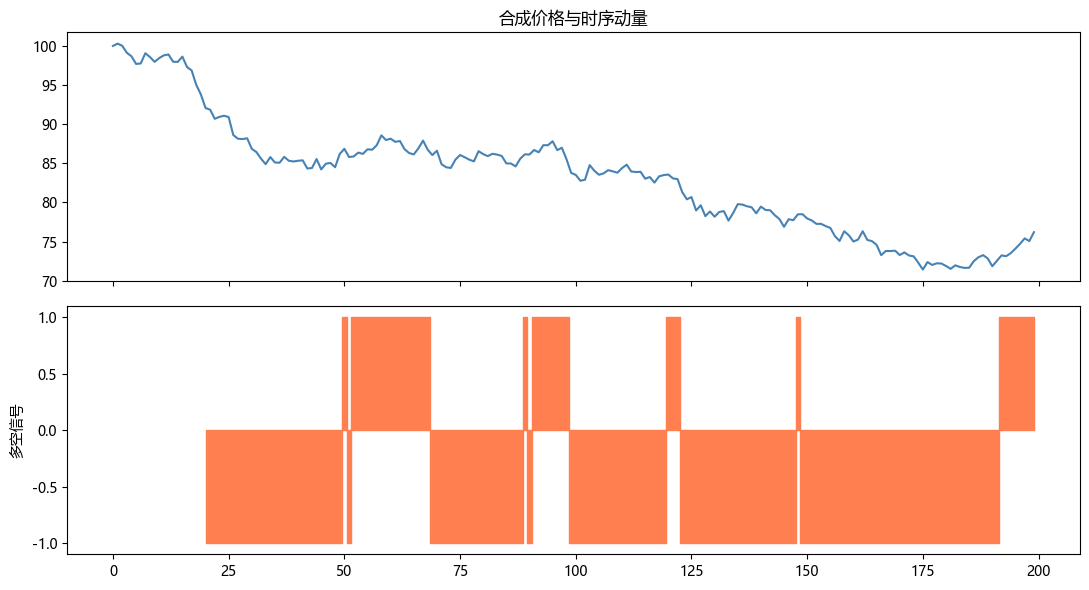

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(syn, color='steelblue'); ax[0].set_title('合成价格与时序动量')
ax[1].fill_between(range(200), ts_sig, 0, color='coral', step='mid')
ax[1].set_ylabel('多空信号'); plt.tight_layout(); plt.show()

## 四、面试要点

- **时序动量与截面动量区别？** 时序按品种自身历史判断多空（绝对方向），截面比较品种间相对强弱。
- **CTA 危机 Alpha 指什么？** 趋势策略在市场剧烈下跌时往往能做空获利，与股票组合相关性低。
- **展期收益来自哪里？** 期货期限结构，贴水（近高远低）下做多移仓获得正展期收益。
- **如何控制震荡市假信号？** 用趋势过滤、信号确认、波动率定标与多品种分散。

## 五、练习

1. 实现波动率倒数定标的仓位。
2. 对比不同 lookback 的时序动量表现。
3. 计算跨品种价差套利信号。
4. 用真实期货主力连续合约回测。